**setup**

In [1]:
%load_ext autoreload
%autoreload 2

import time

import pandas as pd

from fxml.db.connection import connect
from fxml.db.schema import init_db
from fxml.evaluation import plots
from fxml.evaluation.portfolio import combine_equal_weight, portfolio_stats, return_correlations
from fxml.training.experiment import Settings
from fxml.training.pipeline import ExperimentPlan, run_experiment_detailed

plots.apply_style()
conn = connect()
init_db(conn)
PAIRS = ["EURUSD", "GBPUSD", "EURJPY", "GBPJPY", "USDJPY", "USDCAD"]
settings = Settings(horizon=12)
outcomes = {}


**run every pair once (about 10 - 12 minutes)**

In [2]:
for symbol in PAIRS:
    start = time.time()
    plan = ExperimentPlan(name=f"breadth-h12-{symbol}", symbol=symbol,
                          notes="breadth test, pre-registered, run once per pair")
    outcomes[symbol] = run_experiment_detailed(conn, plan, settings, verbose=False)
    s = outcomes[symbol].summary
    print(f"{symbol}: net Sharpe {s['sharpe']:+.2f}, net {s['net_bps_per_trade']:+.2f} bps/trade, "
          f"{s['n_trades']} trades ({(time.time() - start) / 60:.1f} min)")


EURUSD: net Sharpe +0.33, net +0.34 bps/trade, 8060 trades (2.2 min)
GBPUSD: net Sharpe -2.15, net -2.93 bps/trade, 8060 trades (2.1 min)
EURJPY: net Sharpe +0.98, net +1.30 bps/trade, 8060 trades (1.9 min)
GBPJPY: net Sharpe +0.12, net +0.17 bps/trade, 8060 trades (2.0 min)
USDJPY: net Sharpe +0.03, net +0.04 bps/trade, 8060 trades (2.1 min)
USDCAD: net Sharpe -2.20, net -1.88 bps/trade, 8060 trades (2.2 min)


**the per-pair table**

In [3]:
table = pd.DataFrame({s: o.summary for s, o in outcomes.items()}).T.apply(pd.to_numeric, errors="coerce")
table[["n_trades", "gross_bps_per_trade", "net_bps_per_trade", "net_bps_with_0.3_slippage",
       "sharpe", "mean_rank_corr", "max_drawdown"]].round(3)


,n_trades,gross_bps_per_trade,net_bps_per_trade,net_bps_with_0.3_slippage,sharpe,mean_rank_corr,max_drawdown
EURUSD,8060.0,1.019,0.341,0.041,0.333,0.029,-0.070
GBPUSD,8060.0,-2.068,-2.930,-3.230,-2.154,0.006,-0.211
EURJPY,8060.0,2.478,1.305,1.005,0.980,0.020,-0.066
GBPJPY,8060.0,1.544,0.170,-0.130,0.122,0.016,-0.108
USDJPY,8060.0,1.219,0.042,-0.258,0.033,0.008,-0.081
USDCAD,8060.0,-0.758,-1.883,-2.183,-2.196,-0.005,-0.171


**the portfolio and how the pairs relate**

In [4]:
per_bar = {s: o.per_bar for s, o in outcomes.items()}
portfolio = combine_equal_weight(per_bar)
stats = portfolio_stats(portfolio)
print({k: round(v, 4) for k, v in stats.items()})
return_correlations(per_bar).round(2)


{'n_bars': 40214, 'sharpe': -0.8238, 'total_return': -0.0334, 'max_drawdown': -0.05}


,EURUSD,GBPUSD,EURJPY,GBPJPY,USDJPY,USDCAD
EURUSD,1.00,0.10,0.04,0.03,0.07,0.09
GBPUSD,0.10,1.00,0.03,0.11,0.03,0.00
EURJPY,0.04,0.03,1.00,0.38,0.24,-0.00
GBPJPY,0.03,0.11,0.38,1.00,0.14,-0.04
USDJPY,0.07,0.03,0.24,0.14,1.00,0.03
USDCAD,0.09,0.00,-0.00,-0.04,0.03,1.00


**the verdict, and the equity curve**

1. portfolio net Sharpe                 -0.82   (need > 0.6)
2. pairs with net Sharpe > 0            4 of 6      (need >= 4)
3. mean net bps/trade, 0.3 slippage     -0.79   (need > 0)


<Axes: title={'left': 'Equal-weight six-pair portfolio after costs (cumulative log return, %)'}, xlabel='time'>

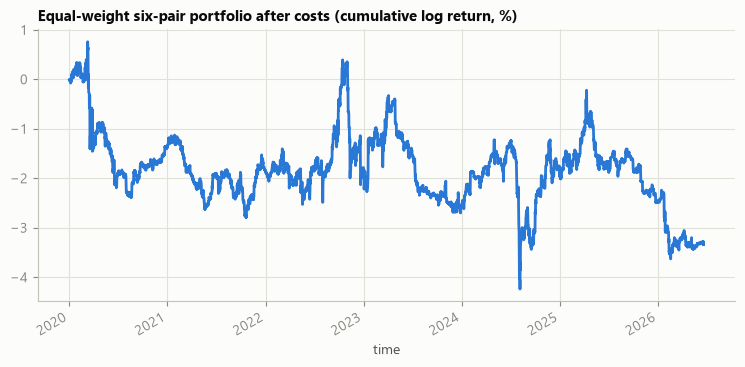

In [5]:
positive = int((table["sharpe"] > 0).sum())
mean_slip = table["net_bps_with_0.3_slippage"].mean()
print(f"1. portfolio net Sharpe                 {stats['sharpe']:+.2f}   (need > 0.6)")
print(f"2. pairs with net Sharpe > 0            {positive} of {len(table)}      (need >= 4)")
print(f"3. mean net bps/trade, 0.3 slippage     {mean_slip:+.2f}   (need > 0)")
(portfolio.cumsum() * 100).plot(color=plots.BLUE, figsize=(9, 4),
                                title="Equal-weight six-pair portfolio after costs (cumulative log return, %)")
